# II.A.2–3 — Sequential pump detection: CUSUM on GARCH residuals and abnormal volume, versus Isolation Forest

**Objective (brief II.A.2–3).**
1. Run a one-sided CUSUM on the standardised residuals $\hat\eta_t$ of an ARMA–GARCH model and on the abnormal
   volume $z^V_t$: $S_t=\max(0,\,S_{t-1}+u_t-k)$, alarm as soon as $S_t>h$, with $h$ calibrated by simulation of the
   in-control average run length $\mathrm{ARL}_0$.
2. Measure the detection rate, the false alarms per day and the detection delay. Does the alarm precede $\tau$?
3. Compare with an Isolation Forest.

**Design (per event).**
* *Training window* $[\tau-30\,\text{d},\ \tau-10\,\text{d})$, 480 hours: fit ARMA(0,1)–GARCH(1,1)–$t$ (the order most
  often selected in II.A.1) and the mean and standard deviation of $\log(1+V_t)$.
* *Monitoring window* $[\tau-10\,\text{d},\ \tau+3\,\text{h}]$: filter $\hat\eta_t$ and $z^V_t$ with the frozen
  parameters and run the detectors hour by hour. After an alarm the statistic is reset to 0.
* Alarms in $[\tau-10\,\text{d},\ \tau-72\,\text{h})$ are **false alarms** (the coin is not yet under pre-pump
  pressure, cf. I.3). An event is **detected** if an alarm fires in $[\tau-72\,\text{h},\ \tau+1\,\text{h}]$, and
  **detected early** if the alarm fires before $\tau$. The **delay** is $t_{\text{alarm}}-\tau$ in hours (negative
  means before the pump).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from sklearn.ensemble import IsolationForest

from pnd_paper import settings, tsmodels
from pnd_paper import stats as S
from pnd_paper.data import pd_log, binance, universe
from pnd_paper.report import Reporter, md, show, close, SERIES

warnings.filterwarnings("ignore")
settings.seed_everything()
R = Reporter("IIA2_cusum_isolation_forest")
SZ = settings.SIZES
ARL0 = 720           # target in-control ARL: one false alarm per 30 days on average
KS_REF = [0.25, 0.5, 1.0]

ev_all = pd_log.binance_btc_events()
ev = (ev_all.assign(h=ev_all.timestamp.dt.floor("h")).sort_values("timestamp")
      .drop_duplicates(["symbol", "h"]).reset_index(drop=True))
panels = binance.build_hourly_panel(universe.universe(ev_all) + ["BTCUSDT"], universe.PANEL_START, universe.PANEL_END)
close_, qv = panels["close"], panels["quote_volume"]

## 1. Per-event filtering

For event $i$ with return series $r_t$ (in %), the frozen model gives $\hat\eta_t=\hat\varepsilon_t/\hat\sigma_t$ on the
monitoring window (the GARCH recursion runs over training and monitoring hours without re-estimation), and
$z^V_t=(\log(1+V_t)-\hat\mu_V)/\hat\sigma_V$.

In [2]:
rng = np.random.default_rng(settings.SEED)
eligible = []
for e in ev.itertuples():
    if e.symbol not in close_.columns:
        continue
    t_star = universe.last_bar_before(e.timestamp)
    tr = close_[e.symbol].loc[e.timestamp - pd.Timedelta(days=30):e.timestamp - pd.Timedelta(days=10)]
    if len(tr) > 450 and tr.notna().mean() > 0.97 and (tr.diff() != 0).mean() > 0.6:
        eligible.append(e)
n_ev = len(eligible) if SZ.cusum_events is None else min(SZ.cusum_events, len(eligible))
sample = [eligible[i] for i in sorted(rng.choice(len(eligible), n_ev, replace=False))]

data = []
for e in sample:
    s = e.symbol
    start, split_t, end = e.timestamp - pd.Timedelta(days=30), e.timestamp - pd.Timedelta(days=10), e.timestamp + pd.Timedelta(hours=3)
    px = close_[s].loc[start:end].ffill()
    r = 100 * np.log(px).diff().fillna(0.0)
    lv = np.log1p(qv[s].loc[start:end].fillna(0.0))
    train = r.index < split_t
    fit = tsmodels.fit_arma_garch(r[train].values, 0, 1)
    eta_all, _ = tsmodels.filter_new(fit, r.values)
    eta = pd.Series(np.r_[np.full(len(r) - len(eta_all), np.nan), eta_all], index=r.index)
    zv = (lv - lv[train].mean()) / lv[train].std(ddof=1)
    mon = ~train
    data.append({"event": e, "fit": fit, "r": r[mon], "eta": eta[mon], "zv": zv[mon], "eta_train": eta[train].dropna(),
                 "zv_train": zv[train], "rel_h": ((r.index[mon] - e.timestamp) / pd.Timedelta(hours=1)).values,
                 "r_train": r[train]})
nus = np.array([d["fit"].params["nu"] for d in data])
md(f"{len(eligible)} events have a usable training window; {n_ev} are monitored "
   f"({'QUICK' if settings.QUICK else 'FULL'} run). Median fitted $\\hat\\nu={np.median(nus):.2f}$.")

404 events have a usable training window; 60 are monitored (QUICK run). Median fitted $\hat\nu=3.12$.

## 2. Calibration of $h$ by simulation of $\mathrm{ARL}_0$

The run length of a CUSUM started at 0 is $N=\inf\{t:S_t>h\}$; $\mathrm{ARL}_0(h,k)=\mathbb E_0[N]$ when the process is
in control. With in-control inputs $u_t$ simulated i.i.d. we estimate $\mathrm{ARL}_0$ by the mean run length over
$M$ simulated paths, and find $h$ such that $\widehat{\mathrm{ARL}}_0(h,k)=720$ hours by bisection
($\mathrm{ARL}_0$ is increasing in $h$).

* For $\hat\eta_t$ the in-control law is the standardised $t_{\hat\nu}$ with $\hat\nu$ the median over events.
* For $z^V_t$ there is no parametric law; we resample the pooled training values of $z^V$ (i.i.d. bootstrap).
  Serial correlation of volume makes the real $\mathrm{ARL}_0$ shorter than the simulated one, which shows up as
  extra false alarms; this is measured below rather than assumed away.

In [3]:
def run_lengths(sampler, h, k, M, cap):
    S_ = np.zeros(M)
    rl = np.full(M, cap, float)
    alive = np.ones(M, bool)
    for t in range(cap):
        S_ = np.maximum(0.0, S_ + sampler(M) - k)
        hit = alive & (S_ > h)
        rl[hit] = t + 1
        alive &= ~hit
        if not alive.any():
            break
    return rl


def calibrate(sampler, k, M, target=ARL0, lo=0.1, hi=40.0, iters=18):
    cap = 8 * target
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        arl = run_lengths(sampler, mid, k, M, cap).mean()
        lo, hi = (mid, hi) if arl < target else (lo, mid)
    return 0.5 * (lo + hi), arl


nu_med = float(np.median(nus))
pool_zv = np.concatenate([d["zv_train"].values for d in data])
samplers = {"eta": lambda M: tsmodels.simulate_t(nu_med, M, rng),
            "zV": lambda M: rng.choice(pool_zv, M)}
calib = []
for stat_name, smp in samplers.items():
    for k in KS_REF:
        h, arl = calibrate(smp, k, SZ.arl_sims)
        calib.append({"input": stat_name, "k": k, "h": h, "simulated ARL0": arl})
calib = pd.DataFrame(calib)
R.table(calib, "cusum_calibration", index=False)
show(calib.set_index(["input", "k"]))

## 3. Detection performance

For each detector we report, over the monitored events: the detection rate $\hat\pi=D/N$ with its exact
Clopper–Pearson 95 % interval (inverting the binomial test), the early-detection rate (alarm before $\tau$), the
false alarms per day in the calm part of the monitoring window, and the median delay.

In [4]:
def cusum_alarms(u, h, k):
    S_, out = 0.0, []
    for i, x in enumerate(u):
        S_ = max(0.0, S_ + (0.0 if np.isnan(x) else x) - k)
        if S_ > h:
            out.append(i)
            S_ = 0.0
    return np.array(out, int)


def evaluate(alarm_fn):
    det, early, delays, fa, calm_days = [], [], [], 0, 0.0
    for d in data:
        idx = alarm_fn(d)
        rel = d["rel_h"]
        calm = rel < -72
        fa += int(calm[idx].sum()) if len(idx) else 0
        calm_days += calm.sum() / 24
        win = idx[(rel[idx] >= -72) & (rel[idx] <= 1)] if len(idx) else idx
        det.append(len(win) > 0)
        early.append(len(win) > 0 and rel[win[0]] < 0)
        delays.append(rel[win[0]] if len(win) else np.nan)
    return np.array(det), np.array(early), np.array(delays), fa / calm_days


def summarise(name, det, early, delays, fa_day):
    ci = st.binomtest(int(det.sum()), len(det)).proportion_ci(method="exact")
    return {"detector": name, "detection rate": det.mean(), "CI low": ci.low, "CI high": ci.high,
            "early detection rate": early.mean(), "false alarms / day": fa_day,
            "median delay (h)": np.nanmedian(delays)}


results, hits = [], {}
for _, c in calib.iterrows():
    col = "eta" if c["input"] == "eta" else "zv"
    det, early, delays, fa = evaluate(lambda d, col=col, c=c: cusum_alarms(d[col].values, c["h"], c["k"]))
    name = f"CUSUM {c['input']} (k={c['k']})"
    results.append(summarise(name, det, early, delays, fa))
    hits[name] = (det, early, delays)
# combined detector: alarm when either CUSUM (k=0.5) fires
ce = calib[(calib.input == "eta") & (calib.k == 0.5)].iloc[0]
cz = calib[(calib.input == "zV") & (calib.k == 0.5)].iloc[0]
det, early, delays, fa = evaluate(lambda d: np.union1d(cusum_alarms(d["eta"].values, ce.h, 0.5), cusum_alarms(d["zv"].values, cz.h, 0.5)))
results.append(summarise("CUSUM eta OR zV (k=0.5)", det, early, delays, fa))
hits["CUSUM eta OR zV (k=0.5)"] = (det, early, delays)

### Empirical calibration (serial dependence preserved)

The simulation above assumes i.i.d. inputs. Volume is strongly autocorrelated, so the simulated $h$ is too low for
$z^V$. A second calibration chooses $h$ so that the **empirical** alarm rate on the pooled *training* windows
(real series, serial dependence included) equals the nominal $24/\mathrm{ARL}_0$ per day. It uses no monitoring data,
so it is still an out-of-sample threshold.

In [5]:
def empirical_h(col_train, k, target=24 / ARL0, lo=0.1, hi=200.0, iters=25):
    series_ = [d[col_train].fillna(0).values for d in data]
    days = sum(len(s_) for s_ in series_) / 24
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        rate = sum(len(cusum_alarms(s_, mid, k)) for s_ in series_) / days
        lo, hi = (lo, mid) if rate < target else (mid, hi)
    return 0.5 * (lo + hi)


h_eta_emp = empirical_h("eta_train", 0.5)
h_zv_emp = empirical_h("zv_train", 0.5)
for name, col, h in (("CUSUM eta, empirical h (k=0.5)", "eta", h_eta_emp), ("CUSUM zV, empirical h (k=0.5)", "zv", h_zv_emp)):
    det, early, delays, fa = evaluate(lambda d, col=col, h=h: cusum_alarms(d[col].values, h, 0.5))
    results.append(summarise(name, det, early, delays, fa))
    hits[name] = (det, early, delays)
md(f"Empirical thresholds: $h_\\eta={h_eta_emp:.2f}$ (simulated: {ce.h:.2f}), $h_{{z^V}}={h_zv_emp:.2f}$ (simulated: {cz.h:.2f}).")

Empirical thresholds: $h_\eta=7.14$ (simulated: 5.79), $h_{z^V}=35.46$ (simulated: 7.66).

### Isolation Forest

Isolation Forest (Liu et al., 2008) isolates points with random axis-parallel splits; anomalies need fewer splits.
With $h(x)$ the path length of $x$ in a tree and $c(n)=2H(n-1)-2(n-1)/n$ the average path length of an unsuccessful
search in a binary search tree of $n$ points, the anomaly score is
$$s(x)=2^{-\mathbb E[h(x)]/c(n)}\in(0,1],$$
close to 1 for anomalies. Features per hour: $r_t$, $|\hat\eta_t|$, $z^V_t$, and 6- and 24-hour rolling sums of
$r_t$ and rolling means of $z^V_t$. A single forest is trained on the pooled training windows of all events, and
its alarm threshold is the $1-1/720$ quantile of the training scores, which gives the same nominal false-alarm rate
as the CUSUMs. The hyperparameters `n_estimators` $\in\{100,300\}$ and `max_samples` $\in\{256, 1024\}$ are
chosen to minimise the false-alarm rate on the training events from the *train* split only.

In [6]:
def iso_features(r, eta, zv):
    f = pd.DataFrame({"r": r.values, "abs_eta": np.abs(eta.values), "zv": zv.values}, index=r.index)
    for w in (6, 24):
        f[f"r_sum_{w}"] = f.r.rolling(w, min_periods=1).sum()
        f[f"zv_mean_{w}"] = f.zv.rolling(w, min_periods=1).mean()
    return f.fillna(0.0)


train_feats = pd.concat([iso_features(d["r_train"], d["eta_train"].reindex(d["r_train"].index), d["zv_train"]) for d in data])
mon_feats = [iso_features(d["r"], d["eta"], d["zv"]) for d in data]
best = None
for n_est in (100, 300):
    for ms in (256, 1024):
        iso = IsolationForest(n_estimators=n_est, max_samples=ms, random_state=settings.SEED).fit(train_feats)
        thr = np.quantile(-iso.score_samples(train_feats), 1 - 1 / ARL0)
        fa_rate = np.mean([((-iso.score_samples(f[d["rel_h"] < -72]) > thr).mean())
                           for f, d in zip(mon_feats, data) if d["event"].split == "train"])
        if best is None or fa_rate < best[0]:
            best = (fa_rate, n_est, ms, iso, thr)
_, n_est, ms, iso, thr = best
det, early, delays, fa = evaluate(lambda d, i=None: np.where(-iso.score_samples(mon_feats[data.index(d)]) > thr)[0])
results.append(summarise(f"Isolation Forest (n={n_est}, max_samples={ms})", det, early, delays, fa))
hits["Isolation Forest"] = (det, early, delays)

res = pd.DataFrame(results).set_index("detector")
R.table(res, "detection_performance")
show(res, "{:.3f}")

,detection rate,CI low,CI high,early detection rate,false alarms / day,median delay (h)
detector,,,,,,
CUSUM eta (k=0.25),0.467,0.337,0.600,0.450,0.079,-2.504
CUSUM eta (k=0.5),0.433,0.306,0.568,0.400,0.074,-4.253
CUSUM eta (k=1.0),0.367,0.246,0.501,0.350,0.069,-1.003
CUSUM zV (k=0.25),0.733,0.603,0.839,0.667,0.400,-11.469
CUSUM zV (k=0.5),0.717,0.586,0.825,0.650,0.388,-6.004
CUSUM zV (k=1.0),0.700,0.568,0.812,0.633,0.293,-1.001
CUSUM eta OR zV (k=0.5),0.767,0.640,0.866,0.750,0.448,-13.981
"CUSUM eta, empirical h (k=0.5)",0.333,0.217,0.467,0.317,0.052,-1.002
"CUSUM zV, empirical h (k=0.5)",0.133,0.059,0.246,0.117,0.055,-55.744


### Paired comparison of detectors

The same events are monitored by all detectors, so detection indicators are paired. The exact McNemar test uses
the discordant counts $n_{10}$ (detected by A only) and $n_{01}$ (B only): under $H_0$ "equal detection
probability", $n_{10}\mid n_{10}+n_{01}\sim\mathrm{Bin}(n_{10}+n_{01},1/2)$.

In [7]:
nominal_day = 24 / ARL0
fair = res[(~res.index.str.startswith("Isolation")) & (res["false alarms / day"] <= 3 * nominal_day)]
best_cusum = fair["detection rate"].idxmax()
m = S.mcnemar(hits[best_cusum][0], hits["Isolation Forest"][0])
md(f"Among CUSUM variants whose observed false-alarm rate stays within three times the nominal rate, the best "
   f"detection rate is achieved by **{best_cusum}** ({res.loc[best_cusum, 'detection rate']:.1%}, "
   f"{res.loc[best_cusum, 'false alarms / day']:.3f} false alarms/day) versus Isolation Forest "
   f"({res.filter(like='Isolation', axis=0)['detection rate'].iloc[0]:.1%}). McNemar: $n_{{10}}={m['n10']}$, "
   f"$n_{{01}}={m['n01']}$, ${S.fmt_p(m['p'])}$ → {S.decision(m['p'])}.")
nominal = 24 / ARL0
md(f"Nominal false-alarm rate implied by $\\mathrm{{ARL}}_0=720$ h: {nominal:.3f} per day.")

Among CUSUM variants whose observed false-alarm rate stays within three times the nominal rate, the best detection rate is achieved by **CUSUM eta (k=0.25)** (46.7%, 0.079 false alarms/day) versus Isolation Forest (23.3%). McNemar: $n_{10}=16$, $n_{01}=2$, $p=0.001$ → reject $H_0$ at $\alpha=0.05$.

Nominal false-alarm rate implied by $\mathrm{ARL}_0=720$ h: 0.033 per day.

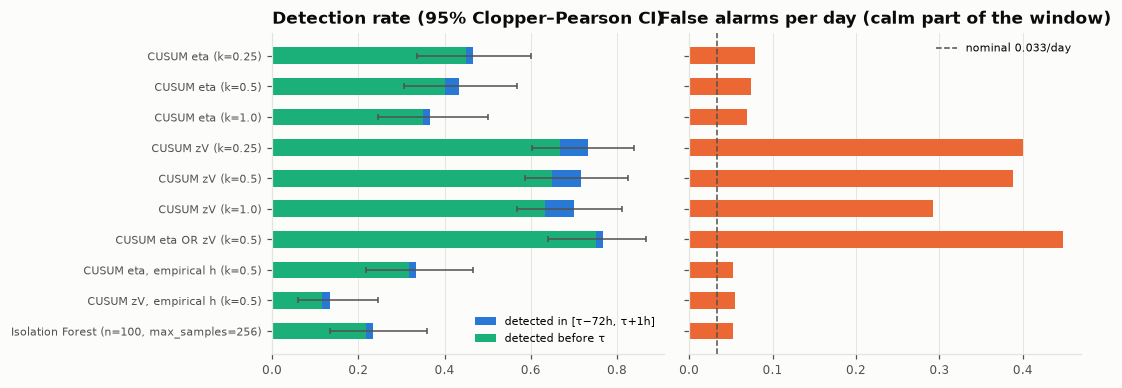

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
names = res.index.tolist()
y = np.arange(len(names))
axes[0].barh(y, res["detection rate"], color=SERIES[0], height=0.55, label="detected in [τ−72h, τ+1h]")
axes[0].barh(y, res["early detection rate"], color=SERIES[2], height=0.55, label="detected before τ")
axes[0].errorbar(res["detection rate"], y, xerr=[res["detection rate"] - res["CI low"], res["CI high"] - res["detection rate"]],
                 fmt="none", ecolor="#52514e", capsize=2, lw=1)
axes[0].set_yticks(y, names, fontsize=7)
axes[0].invert_yaxis()
axes[0].set_title("Detection rate (95% Clopper–Pearson CI)")
axes[0].legend(loc="lower right", fontsize=7)
axes[0].grid(axis="y", visible=False)
axes[1].barh(y, res["false alarms / day"], color=SERIES[1], height=0.55)
axes[1].axvline(nominal, color="#52514e", ls="--", lw=1, label=f"nominal {nominal:.3f}/day")
axes[1].set_yticks(y, [""] * len(names))
axes[1].invert_yaxis()
axes[1].set_title("False alarms per day (calm part of the window)")
axes[1].legend(fontsize=7)
axes[1].grid(axis="y", visible=False)
R.fig(fig, "detection_vs_false_alarms")
close(fig)

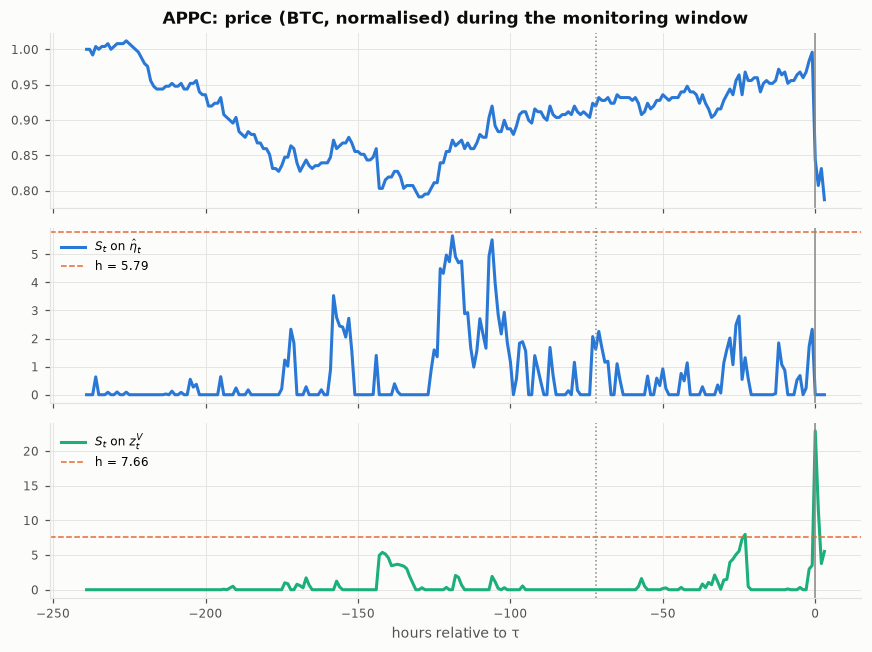

In [9]:
d0 = max(data, key=lambda d: d["zv"].iloc[-6:].max())
e0 = d0["event"]
Se, Sz = [], []
s1 = s2 = 0.0
for a, b in zip(d0["eta"].fillna(0).values, d0["zv"].values):
    s1 = max(0.0, s1 + a - 0.5)
    s2 = max(0.0, s2 + b - 0.5)
    Se.append(s1)
    Sz.append(s2)
    s1 = 0.0 if s1 > ce.h else s1
    s2 = 0.0 if s2 > cz.h else s2
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
axes[0].plot(d0["rel_h"], np.exp(np.cumsum(d0["r"].values / 100)), color=SERIES[0])
axes[0].set_title(f"{e0.coin}: price (BTC, normalised) during the monitoring window")
axes[1].plot(d0["rel_h"], Se, color=SERIES[0], label=r"$S_t$ on $\hat\eta_t$")
axes[1].axhline(ce.h, color=SERIES[1], ls="--", lw=1, label=f"h = {ce.h:.2f}")
axes[1].legend(loc="upper left")
axes[2].plot(d0["rel_h"], Sz, color=SERIES[2], label=r"$S_t$ on $z^V_t$")
axes[2].axhline(cz.h, color=SERIES[1], ls="--", lw=1, label=f"h = {cz.h:.2f}")
axes[2].legend(loc="upper left")
axes[2].set_xlabel("hours relative to τ")
for a in axes:
    a.axvline(-72, color="#8a8985", lw=1, ls=":")
    a.axvline(0, color="#8a8985", lw=1)
R.fig(fig, "example_event")
close(fig)

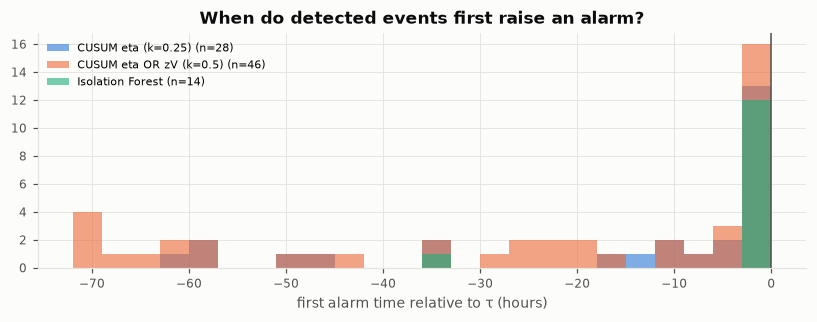

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3))
for i, name in enumerate([best_cusum, "CUSUM eta OR zV (k=0.5)", "Isolation Forest"]):
    dl = hits[name][2]
    dl = dl[np.isfinite(dl)]
    ax.hist(dl, bins=np.arange(-72, 3, 3), alpha=0.6, color=SERIES[i], label=f"{name} (n={len(dl)})")
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlabel("first alarm time relative to τ (hours)")
ax.set_title("When do detected events first raise an alarm?")
ax.legend(fontsize=7)
R.fig(fig, "delays")
close(fig)

## 4. Interpretation (QUICK run: 60 events, 200 ARL simulations)

* **Calibration matters as much as the detector.** With $h$ simulated under i.i.d. inputs, the CUSUM on $\hat\eta_t$
  keeps close to its nominal false-alarm rate (0.07–0.08 per day against 0.033 nominal): GARCH filtering removes
  most of the dependence, as II.A.1 showed. The CUSUM on $z^V_t$ produces about 0.4 false alarms per day, twelve
  times the nominal rate, because volume is strongly autocorrelated and the i.i.d. simulation understates the
  in-control run length. With the threshold calibrated on the real training series, $h_{z^V}$ rises from about 7.7
  to 35, and the false alarms fall to the nominal level. So does detection, to 13 %.
* **At comparable false-alarm rates the residual CUSUM is the best detector.** CUSUM on $\hat\eta_t$ with $k=0.25$
  detects about 47 % of pumps in the 72 hours before $\tau$ (95 % CI 34–60 %), and most of these alarms fire
  **before** the announcement (45 % of events), with a median lead of 2–4 hours. Isolation Forest, calibrated to the
  same nominal rate, detects 23 %. The exact McNemar test rejects equal detection ($p\approx0.001$; 16 events
  detected only by CUSUM against 2 only by the forest).
* **Does the alarm precede $\tau$?** Often, but only by a few hours. The alarms track the last part of the
  pre-pump drift found in I.3 (abnormal returns and volume in the last 6–24 hours), not the slow accumulation 2–3
  days before, which is too gradual to be told apart from noise hour by hour. A surveillance desk would get a lead
  of a few hours on roughly 40 % of pumps, at the price of about one false alarm per coin every two weeks.
* **Smaller $k$ helps.** CUSUM is optimal for detecting a shift of size $2k$ in the mean. Pre-pump shifts in
  $\hat\eta_t$ are small and persistent, so $k=0.25$ beats $k=1$.
* **Why the forest does worse.** Isolation Forest scores each hour separately and has no memory, so it cannot
  accumulate weak evidence over consecutive hours as CUSUM does. It mostly flags the pump hour itself (median delay
  about 0 h).

**Limitations.** False-alarm rates observed in the monitoring window exceed their nominal value even for the
residual CUSUM: the 20-day training window does not capture every regime of the following 10 days. "Calm" hours
10 to 3 days before the pump are assumed free of manipulation, although some insiders may already be active (I.3
found no significant drift that early). With 60 events (QUICK run) the intervals are wide.